# CelebA: разведочный анализ данных

CSV заранее собрана из [разметки Google Drive](https://drive.google.com/drive/folders/0B7EVK8r0v71pOC0wOVZlQnFfaGs?resourcekey=0-pEjrQoTrlbjZJO2UL8K_WQ).
Таблицы объединили по имени фотографии. Разбиение данных выполним отдельно при обучении.
Одна строка — одна фотография. Все данные уже лежат локально в папке `data/` в корне репозитория.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance, ImageOps

data = pd.read_csv("../data/celeba.csv")
print("Строк и колонок:", data.shape)

Строк и колонок: (202599, 66)


In [2]:
data.head()

,image_id,identity,5_o_Clock_Shadow,Arched_Eyebrows,Attractive,Bags_Under_Eyes,Bald,Bangs,Big_Lips,Big_Nose,...,aligned_lefteye_x,aligned_lefteye_y,aligned_righteye_x,aligned_righteye_y,aligned_nose_x,aligned_nose_y,aligned_leftmouth_x,aligned_leftmouth_y,aligned_rightmouth_x,aligned_rightmouth_y
0,000001.jpg,2880,-1,1,1,-1,-1,-1,-1,-1,...,69,109,106,113,77,142,73,152,108,154
1,000002.jpg,2937,-1,-1,-1,1,-1,-1,-1,1,...,69,110,107,112,81,135,70,151,108,153
2,000003.jpg,8692,-1,-1,-1,-1,-1,-1,1,-1,...,76,112,104,106,108,128,74,156,98,158
3,000004.jpg,5805,-1,-1,1,-1,-1,-1,-1,-1,...,72,113,108,108,101,138,71,155,101,151
4,000005.jpg,9295,-1,1,1,-1,-1,-1,1,-1,...,66,114,112,112,86,119,71,147,104,150


## 1. Сводная статистика и поля

`describe()` показывает число значений, среднее, минимум, максимум и квартильные границы.
Посмотрим координаты и размеры рамки лица в пикселях.
Номер человека — категория: считать его среднее бессмысленно.

In [3]:
box_columns = ["bbox_x", "bbox_y", "bbox_width", "bbox_height"]
data[box_columns].describe()

,bbox_x,bbox_y,bbox_width,bbox_height
count,202599.000000,202599.000000,202599.000000,202599.000000
mean,156.764564,84.335505,194.754061,268.922329
std,164.518135,76.067284,141.770066,195.664936
min,1.000000,0.000000,0.000000,0.000000
25%,69.000000,44.000000,120.000000,166.000000
50%,110.000000,68.000000,164.000000,227.000000
75%,181.000000,98.000000,221.000000,306.000000
max,3840.000000,1858.000000,3827.000000,5299.000000


| Поля | Что означают |
|---|---|
| `image_id` | Имя фотографии |
| `identity` | Номер человека; у одного человека бывает несколько фото |
| 40 атрибутов | Метки внешнего вида: `1` — есть признак, `−1` — нет; после обработки заменяем `−1` на `0` |
| `bbox_*` | Положение и размер рамки лица на исходном фото |
| `original_*`, `aligned_*` | Координаты глаз, носа и уголков рта на исходном и выровненном фото |

В атрибутах, например, `Young` — метка молодого внешнего вида, `Male` — метка пола,
`Smiling` — улыбка, `Eyeglasses` — очки, `Blurry` — размытие, `Wearing_Hat` — головной убор.

## 2. Подозрительные значения и очистка

Рамка с нулевой или отрицательной шириной/высотой непригодна для анализа разметки.
Посмотрим такие строки. Просто большие значения автоматически ошибками не считаем:
исходные фотографии могут иметь разные размеры.

In [4]:
bad_boxes = (data["bbox_width"] <= 0) | (data["bbox_height"] <= 0)
print("Повторов имён файлов:", data["image_id"].duplicated().sum())
print("Строк с некорректным размером рамки:", bad_boxes.sum())
data.loc[bad_boxes, ["image_id", "identity", "bbox_width", "bbox_height"]]

Повторов имён файлов: 0
Строк с некорректным размером рамки: 1


,image_id,identity,bbox_width,bbox_height
101282,101283.jpg,9571,0,0


In [5]:
rows_before = len(data)
data = data.loc[~bad_boxes].drop_duplicates(subset="image_id").copy()
print("Убрано строк:", rows_before - len(data))
print("Осталось строк:", len(data))

Убрано строк: 1
Осталось строк: 202598


Исключили одну строку: `101283.jpg`, рамка `0 × 0`. Это проблема разметки рамки,
а не доказательство, что сама фотография плохая. Для текущего анализа используем
202 598 строк; исходная CSV осталась без изменений.

## 3. Пропуски

После очистки проверим NaN — отсутствующие значения. Метка `−1` у атрибута не является NaN.

In [6]:
print("Пропущенных значений:", data.isna().sum().sum())

Пропущенных значений: 0


Пропусков нет, поэтому ничего не заполняем. Добавлять заполнение ради самого шага не нужно.

После работы с пропусками переведём все 40 атрибутов в удобный формат: `1` — признак есть, `0` — нет. Номер человека и координаты не меняем.

In [7]:
attribute_columns = data.loc[:, "5_o_Clock_Shadow":"Young"].columns
data[attribute_columns] = data[attribute_columns].replace({-1: 0})
data[attribute_columns].head()

,5_o_Clock_Shadow,Arched_Eyebrows,Attractive,Bags_Under_Eyes,Bald,Bangs,Big_Lips,Big_Nose,Black_Hair,Blond_Hair,...,Sideburns,Smiling,Straight_Hair,Wavy_Hair,Wearing_Earrings,Wearing_Hat,Wearing_Lipstick,Wearing_Necklace,Wearing_Necktie,Young
0,0,1,1,0,0,0,0,0,0,0,...,0,1,1,0,1,0,1,0,0,1
1,0,0,0,1,0,0,0,1,0,0,...,0,1,0,0,0,0,0,0,0,1
2,0,0,0,0,0,0,1,0,0,0,...,0,0,0,1,0,0,0,0,0,1
3,0,0,1,0,0,0,0,0,0,0,...,0,0,1,0,1,0,1,1,0,1
4,0,1,1,0,0,0,1,0,0,0,...,0,0,0,0,0,0,1,0,0,1


## 4. Несколько наблюдений о данных

Сначала посмотрим, сколько фотографий приходится на человека. Это важно для распознавания:
модель должна узнавать человека по разным снимкам.

Людей: 10177
Фото на человека: минимум 1 , медиана 21.0 , максимум 35


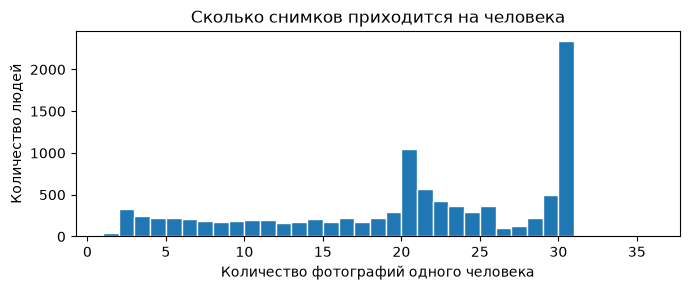

In [8]:
photos_per_person = data["identity"].value_counts()
print("Людей:", len(photos_per_person))
print("Фото на человека: минимум", photos_per_person.min(),
      ", медиана", photos_per_person.median(), ", максимум", photos_per_person.max())

photos_per_person.plot.hist(bins=range(1, 37), figsize=(7, 3), edgecolor="white")
plt.xlabel("Количество фотографий одного человека")
plt.ylabel("Количество людей")
plt.title("Сколько снимков приходится на человека")
plt.tight_layout()
plt.show()

In [9]:
# Считаем людей, у которых ровно 1 или 35 фотографий.
people_with_one_photo = (photos_per_person == 1).sum()
people_with_35_photos = (photos_per_person == 35).sum()

print("Людей с одной фотографией:", people_with_one_photo)
print("Людей с 35 фотографиями:", people_with_35_photos)

Людей с одной фотографией: 44
Людей с 35 фотографиями: 3


**44 человека представлены одной фотографией, а 3 человека — 35 фотографиями каждый.**
Медиана — 21 фотография на человека.

Это дисбаланс классов: при обычном обучении модель чаще видит людей с большим числом
снимков и может хуже узнавать тех, чьих фотографий мало. Поэтому при формировании
обучающих примеров людей можно выбирать равномернее.

Для человека с одним снимком нельзя составить пару разных исходных фотографий
этого человека — такие пары нужны, чтобы учиться узнавать его в разных условиях.

In [10]:
attributes = ["Young", "Male", "Smiling", "Eyeglasses", "Blurry", "Wearing_Hat"]
attribute_share = data[attributes].mean().mul(100).round(1)
attribute_share.rename("Доля фото с меткой, %").to_frame()

,"Доля фото с меткой, %"
Young,77.4
Male,41.7
Smiling,48.2
Eyeglasses,6.5
Blurry,5.1
Wearing_Hat,4.8


В разметке `Young` встречается примерно у 77% фотографий, а очки, размытие
и головной убор — примерно у 5–7%. Эти условия представлены реже: при оценке будущей
модели на них стоит смотреть отдельно. Это статистика меток, не проверка качества всех фото.

## 5. Корреляции

Возьмём шесть понятных атрибутов. Корреляция показывает, как связаны их метки:
ближе к `1` — чаще встречаются вместе, ближе к `−1` — связь обратная,
ближе к `0` — слабая линейная связь. Корреляция не доказывает причину.
Номера людей сюда не включаем.

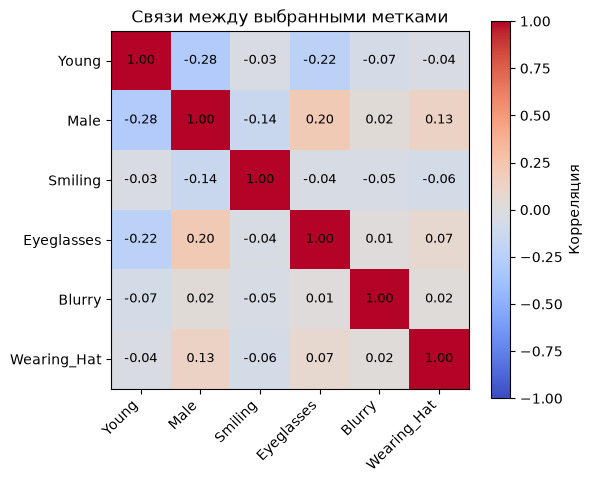

In [11]:
correlations = data[attributes].corr()
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(correlations, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(attributes)), attributes, rotation=45, ha="right")
ax.set_yticks(range(len(attributes)), attributes)
for i in range(len(attributes)):
    for j in range(len(attributes)):
        ax.text(j, i, f"{correlations.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(image, ax=ax, label="Корреляция")
ax.set_title("Связи между выбранными метками")
plt.tight_layout()
plt.show()

Большинство связей между выбранными метками слабые. Например, `Young` и
`Eyeglasses` имеют корреляцию около −0,22: метка очков реже встречается вместе с `Young`.
По этому нельзя делать вывод, что один признак вызывает другой.

## 6. Аугментации

Аугментация — небольшое изменение фотографии, которое создаёт дополнительный
обучающий пример того же человека. Посмотрим три варианта на двух локальных снимках.
Исходные файлы не меняем.

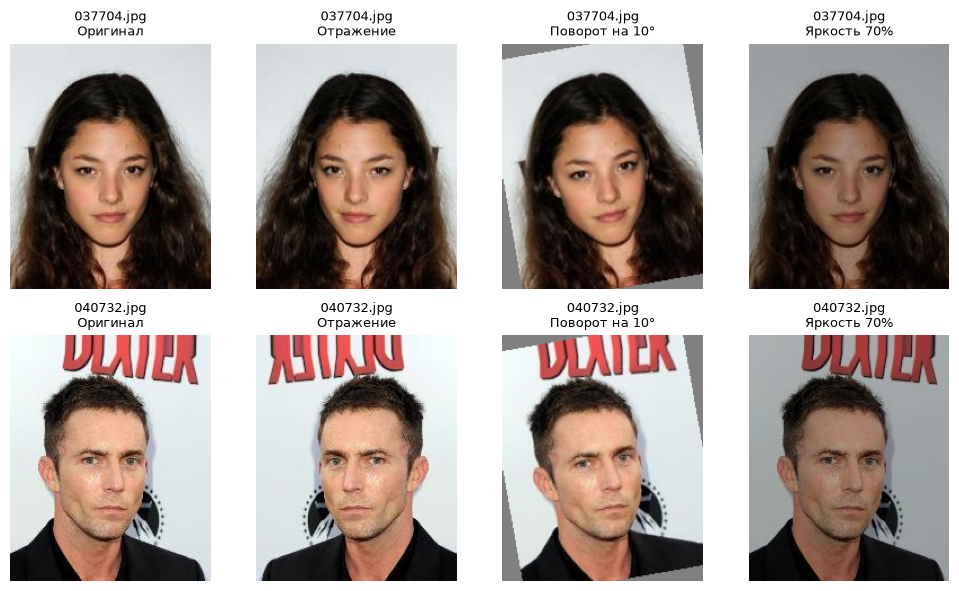

In [12]:
image_paths = sorted(Path("../data/sample_aligned").glob("*.jpg"))[:2]
fig, axes = plt.subplots(2, 4, figsize=(10, 6))

for row, path in enumerate(image_paths):
    with Image.open(path) as image:
        photo = image.convert("RGB")
    variants = [
        ("Оригинал", photo),
        ("Отражение", ImageOps.mirror(photo)),
        ("Поворот на 10°", photo.rotate(10, resample=Image.Resampling.BILINEAR,
                                       fillcolor=(128, 128, 128))),
        ("Яркость 70%", ImageEnhance.Brightness(photo).enhance(0.7)),
    ]
    for column, (title, variant) in enumerate(variants):
        axes[row, column].imshow(variant)
        axes[row, column].set_title(f"{path.name}\n{title}", fontsize=9)
        axes[row, column].axis("off")

plt.tight_layout()
plt.show()

| Способ | Для чего подходит |
|---|---|
| Отражение по горизонтали | Показывает модели отражённый снимок; личность остаётся той же |
| Небольшой поворот | Имитирует наклон головы или камеры; сильные повороты могут испортить пример |
| Изменение яркости | Имитирует более тёмный кадр; слишком сильное затемнение скрывает детали лица |

Эти варианты можно попробовать при обучении распознавания лиц. Пока мы проверили
их визуально; улучшение качества модели нужно будет подтвердить экспериментом.
Аугментации применяют к обучающим снимкам. Они не заменяют разные исходные фотографии человека.

Здесь меняем только изображения для recognition. Если использовать их для обучения
детекции или ключевых точек, при повороте и отражении нужно также преобразовать
координаты разметки, а при отражении — поменять местами левые и правые точки.

## Короткий вывод

- Таблица подходит для первого анализа распознавания лиц: есть люди, атрибуты и координаты разметки.
- Убрана одна строка с нулевой рамкой; NaN не обнаружены.
- Число снимков на человека различается, а некоторые условия встречаются редко.
- Показаны отражение, небольшой поворот и изменение яркости; их пользу проверим при обучении.
- Качество всех изображений по одним таблицам и двум примерам оценить нельзя.